In [1]:
import pickle as pkl
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 200
plt.rcParams['pdf.fonttype'] = '42'

import pandas as pd
import seaborn as sns

import sys
sys.path.append('/scratch/gpfs/PRITYKIN/brendan/domino/python_modules')

from generic_plotting_functions import *
from plot_attributions_and_fimo import *

In [2]:
with open('/scratch/gpfs/PRITYKIN/brendan/domino/scripts/motif_synergy/new_synergy_rerun/final_rc_cooperativity_scores_rerun.pkl', 'rb') as f:
    motif_rc_cooperativity_scores = pkl.load(f)

coop_dict = dict()
for k, v in motif_rc_cooperativity_scores.items():
    key = k[0] + ', ' + k[1]
    coop_dict[key] = v
plot_df = pd.DataFrame(coop_dict).T

plot_df_T = plot_df.copy().T
top20_means = plot_df_T.apply(lambda col: col.nlargest(20).mean())
top20_means_df = pd.DataFrame([top20_means])


In [7]:
def df_to_matrix(df):
    s = df.iloc[0]
    s.index = s.index.str.split(", ", expand=True)
    matrix = s.rename_axis(['row', 'col']).unstack('col')
    matrix = matrix.T
    return matrix

synergy_df = df_to_matrix(top20_means_df)
synergy_df.columns = [c.replace('_fwd', '-FA').replace('_rev', '-RA') for c in synergy_df.copy().columns]
synergy_df.index = [c.replace('_fwd', '-FB').replace('_rev', '-RB') for c in synergy_df.copy().index]

## Examples for distance

In [14]:
def plot_sig_synergy(mA, mB, mean_color, ax, ylim=[-0.1, 0.7]):
    ax.plot(motif_rc_cooperativity_scores[(f'{mA}_fwd', f'{mB}_fwd')][:150], lw=2, alpha=0.2, c='gray')
    ax.plot(motif_rc_cooperativity_scores[(f'{mA}_fwd', f'{mB}_rev')][:150], lw=2, alpha=0.2, c='gray')
    ax.plot(motif_rc_cooperativity_scores[(f'{mB}_fwd', f'{mA}_fwd')][:150], lw=2, alpha=0.2, c='gray')
    ax.plot(motif_rc_cooperativity_scores[(f'{mB}_fwd', f'{mA}_rev')][:150], lw=2, alpha=0.2, c='gray')
    ax.plot(motif_rc_cooperativity_scores[(f'{mA}_rev', f'{mB}_fwd')][:150], lw=2, alpha=0.2, c='gray')
    ax.plot(motif_rc_cooperativity_scores[(f'{mA}_rev', f'{mB}_rev')][:150], lw=2, alpha=0.2, c='gray')
    ax.plot(motif_rc_cooperativity_scores[(f'{mB}_rev', f'{mA}_fwd')][:150], lw=2, alpha=0.2, c='gray')
    ax.plot(motif_rc_cooperativity_scores[(f'{mB}_rev', f'{mA}_rev')][:150], lw=2, alpha=0.2, c='gray')
    
    synergy_tracks = list()
    for k in motif_rc_cooperativity_scores:
        if f'{mA}' in str(k) and f'{mB}' in str(k):
            synergy_tracks.append(motif_rc_cooperativity_scores[k][:150])
    synergy_arr = np.array(synergy_tracks)
    mean_synergy_arr = synergy_arr.mean(axis=0)
    ax.plot(mean_synergy_arr, alpha=0.9, lw=2.5, c=mean_color)
    
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    for spine in ['bottom', 'left']:
        ax.spines[spine].set_linewidth(1)
        ax.spines[spine].set_color('black')

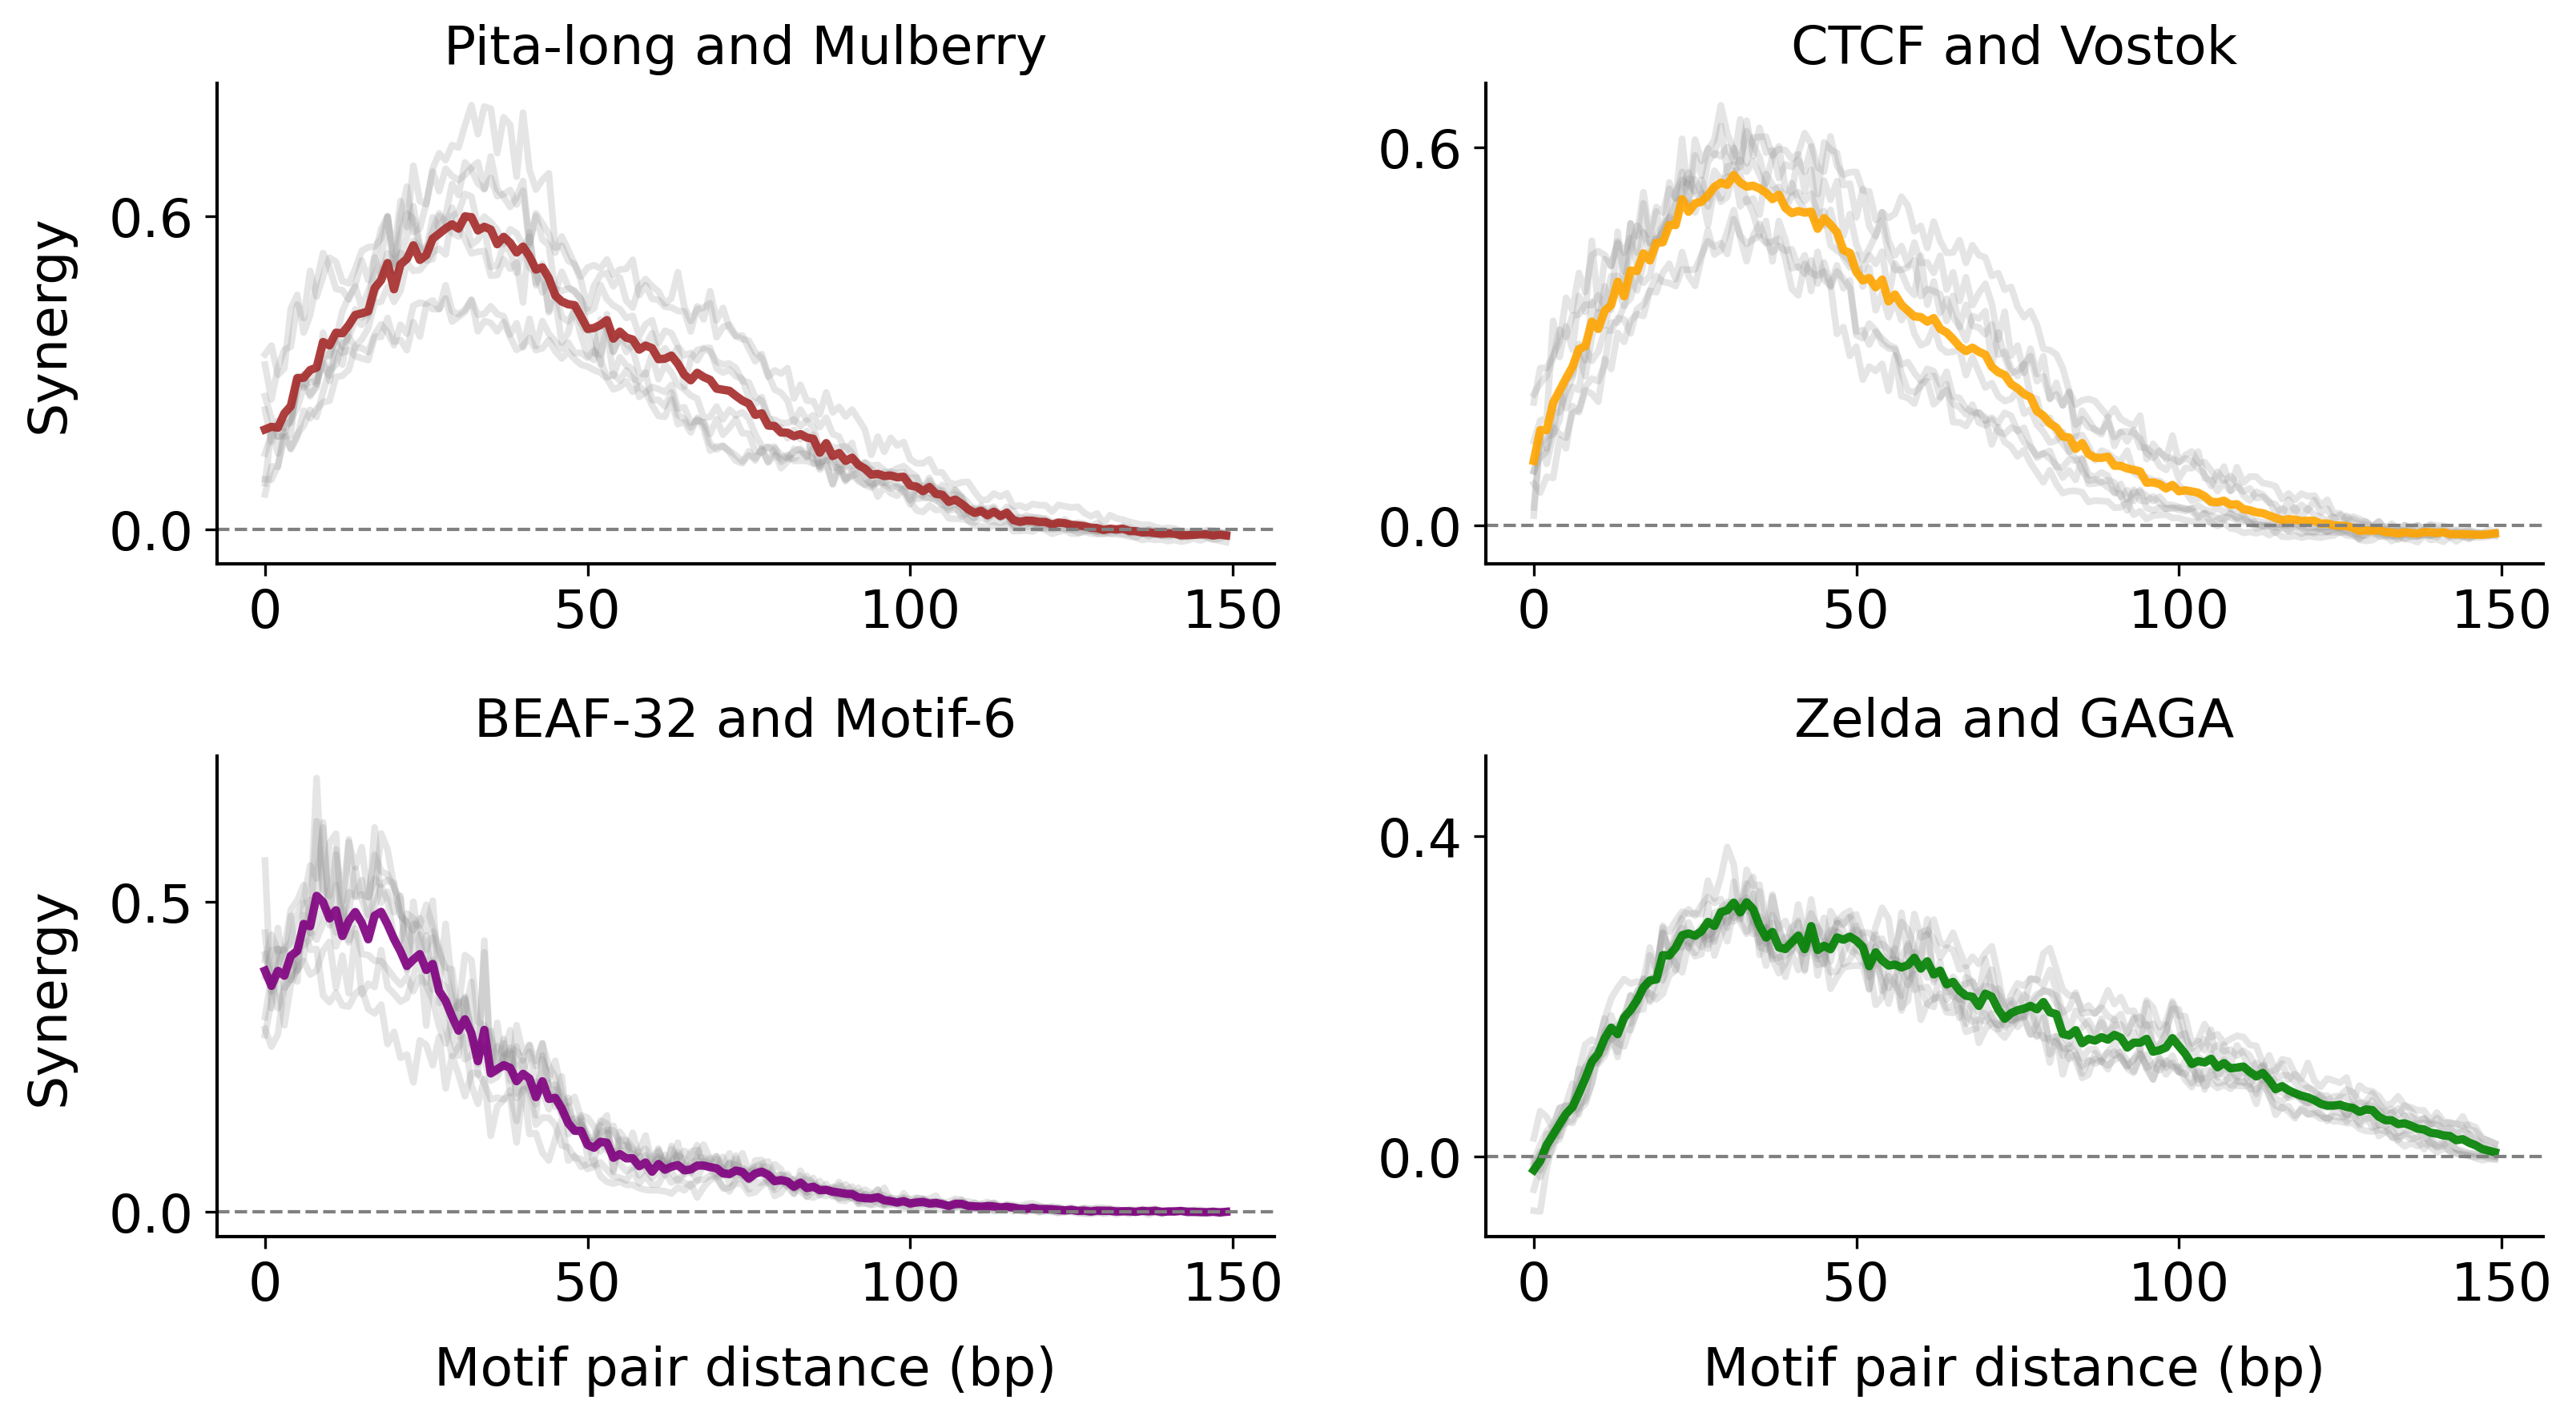

In [15]:
old_rc = plt.rcParams.copy()
plt.rcParams['font.size'] = 16

fig, axs = init_subplots_exact(4,2,sharex=True, dpi=300, x_ratios=[1.1]*2, y_ratios=[0.5]*2, yspace=1.4, xspace=1.2)
ylim=[-0.1, 0.7]

ax = axs[0]
plt.sca(ax)
mA, mB, mean_color = 'Pita-long', 'Mulberry', 'brown'
plot_sig_synergy(mA, mB, mean_color, ax=ax)
plt.title(f'{mA} and {mB}', fontsize=16)
plt.yticks([0, 0.6])

ax = axs[1]
plt.sca(ax)
mA, mB, mean_color = 'CTCF', 'Vostok', 'orange'
plot_sig_synergy(mA, mB, mean_color, ax=ax)
plt.title(f'{mA} and {mB}', fontsize=16)
plt.yticks([0, 0.6])


ax = axs[2]
plt.sca(ax)
mA, mB, mean_color = 'BEAF-32', 'Motif-6', 'purple'
plot_sig_synergy(mA, mB, mean_color, ax=ax)
plt.title(f'{mA} and {mB}', fontsize=16)
plt.xlabel('Motif pair distance (bp)', labelpad=10)
plt.yticks([0, 0.5])


ax = axs[3]
plt.sca(ax)
mA, mB, mean_color = 'Zelda', 'GAGA', 'green'
plot_sig_synergy(mA, mB, mean_color, ax=ax)
plt.xlabel('Motif pair distance (bp)', labelpad=10)
plt.title(f'{mA} and {mB}', fontsize=16)
plt.yticks([0, 0.4])
plt.ylim([-0.1, 0.5])


for i, ax in enumerate(axs):
    if i in [0, 2]: ax.set_ylabel("Synergy", labelpad=10) 
    ax.set_xticks([0, 50, 100, 150])
    ax.set_xticklabels([0, 50, 100, 150])

for ax in axs:
    ax.axhline(0, linestyle='--', color='gray', lw=1)
# plt.savefig("plots/many_spacing_preferences.pdf", dpi=300, bbox_inches='tight')
plt.show()
plt.rcParams.update(old_rc)

In [26]:
def synergy_four_categories(motif):
    """
    For a given motif X, gets synergy values four relative orientations with another motif Y:
    - X is first and forward
    - X is first and reverse
    - X is second and forward
    - X is second and reverse
    The orientation of Y can be in either orientation.
    """
    before_mfwd = []
    before_mrev = []
    after_mfwd = []
    after_mrev = []
    
    for col in top20_means_df:
        motifA, motifB = col.split(', ')
    
        # if first motif
        if motifA ==  f'{motif}_fwd':
            before_mfwd.append(top20_means_df.loc[0, col])
        elif motifA == f'{motif}_rev':
            before_mrev.append(top20_means_df.loc[0, col])
    
        # if second
        if motifB == f'{motif}_fwd':
            after_mfwd.append(top20_means_df.loc[0, col])
        elif motifB == f'{motif}_rev':
            after_mrev.append(top20_means_df.loc[0, col])
    
    tmp2 = pd.DataFrame({
        f'FA': before_mfwd,
        f'RA': before_mrev,
        f'FB': after_mfwd,
        f'RB': after_mrev
    })
    
    df_melt2 = tmp2.melt(var_name='group', value_name='value')
    return df_melt2

def synergy_eight_categories(motif):
    """
    For a given motif X, gets synergy values eight relative orientations with another motif Y:
    - X is first and forward, Y second and forward
    - X is first and reverse, Y second and forward
    - X is second and forward, Y first and forward
    - X is second and reverse, Y first and forward
    - X is first and forward, Y second and reverse
    - X is first and reverse, Y second and forward
    - X is second and forward, Y first and forward
    - X is second and reverse, Y first and forward
    """
    before_mfwd_fwd = []
    before_mfwd_rev = []
    before_mrev_fwd = []
    before_mrev_rev = []
    fwd_after_mfwd = []
    rev_after_mfwd = []
    fwd_after_mrev = []
    rev_after_mrev = []
    
    for col in top20_means_df:
        motifA, motifB = col.split(', ')
        
        # if motif is the first motif
        if motifA ==  f'{motif}_fwd':

            # MFF
            if 'fwd' in motifB:
                before_mfwd_fwd.append(top20_means_df.loc[0, col])
            # MFR
            else:
                before_mfwd_rev.append(top20_means_df.loc[0, col])
        elif motifA == f'{motif}_rev':
            # MRF
            if 'fwd' in motifB:
                before_mrev_fwd.append(top20_means_df.loc[0, col])
            # MRR
            else:
                before_mrev_rev.append(top20_means_df.loc[0, col])
    
        # if motif is the second motif
        if motifB == f'{motif}_fwd':

            # FMF
            if 'fwd' in motifA:
                fwd_after_mfwd.append(top20_means_df.loc[0, col])
            # RMF
            else:
                rev_after_mfwd.append(top20_means_df.loc[0, col])
        elif motifB == f'{motif}_rev':
            # FMR
            if 'fwd' in motifA:
                fwd_after_mrev.append(top20_means_df.loc[0, col])
            # RMR
            else:
                rev_after_mrev.append(top20_means_df.loc[0, col])
    
    tmp3 = pd.DataFrame({
        f'FMA-FB': before_mfwd_fwd,
        f'FMA-RB': before_mfwd_rev,
        f'RMA-FB': before_mrev_fwd,
        f'RMA-RB': before_mrev_rev,
        f'FA-FMB': fwd_after_mfwd,
        f'RA-FMB': rev_after_mfwd,
        f'FA-RMB': fwd_after_mrev,
        f'RA-RMB': rev_after_mrev,
    })
    
    df_melt3 = tmp3.melt(var_name='group', value_name='value')
    return df_melt3

## ANOVA test for all motifs

In [27]:
import re

motif_list = set([re.split(r'-[FR]A', x)[0] for x in synergy_df.columns])

/home/byw2/micromamba/envs/domino_vis/lib/python3.10/site-packages/matplotlib/text.py:757: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  posx = float(self.convert_xunits(self._x))
/home/byw2/micromamba/envs/domino_vis/lib/python3.10/site-packages/matplotlib/text.py:758: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  posy = float(self.convert_yunits(self._y))
/home/byw2/micromamba/envs/domino_vis/lib/python3.10/site-packages/matplotlib/text.py:897: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  x = float(self.convert_xunits(self._x))
/home/byw2/micromamba/envs/domino_vis/lib/python3.10/site-packages/matplotlib/text.py:898: FutureWarning: Calling float on a single element Series is deprecated and w

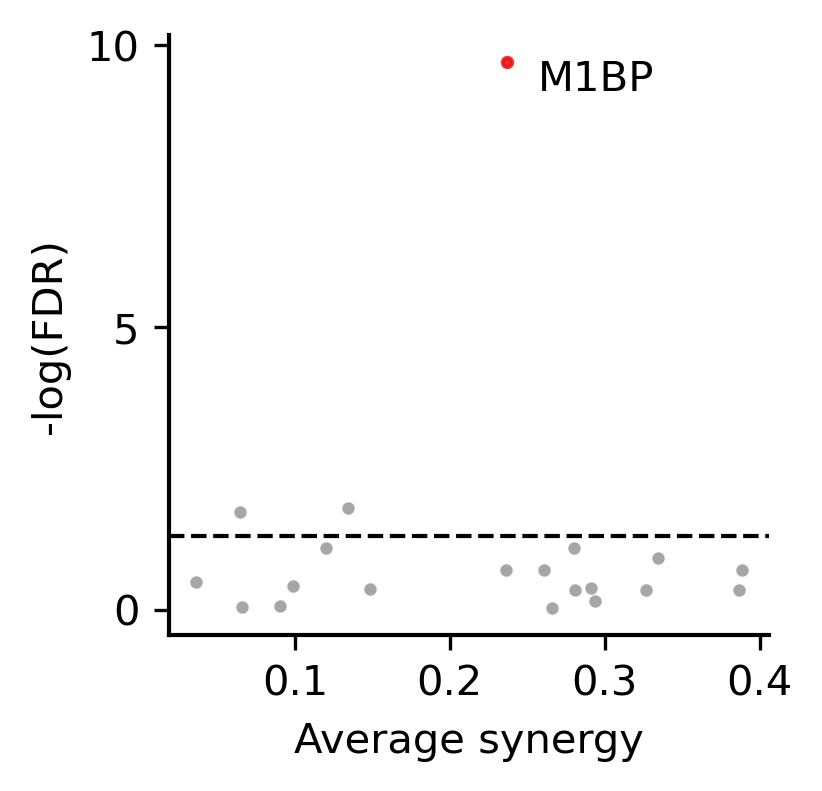

In [28]:
import scipy.stats as stats

average_synergy = list()
pvals = list()
for motif in motif_list:
    four_df = synergy_four_categories(motif)
    average_synergy.append(four_df.value.mean())
    groups = four_df['group'].unique()
    group_data = [four_df[four_df['group'] == g]['value'] for g in groups]
    f_val, p_val = stats.f_oneway(*group_data)
    pvals.append(p_val)

anova_df = pd.DataFrame({
    'motif': list(motif_list),
    'synergy': average_synergy,
    'pval': pvals
})

import statsmodels.stats.multitest as multi
reject, fdr_pvals, _, _ = multi.multipletests(anova_df['pval'], method='fdr_bh')
anova_df['adj_pval'] = fdr_pvals
anova_df['significance'] = -np.log10(anova_df['adj_pval'])

fig, ax = init_subplots_exact(1,1, dpi=300, y_ratios=[0.5], x_ratios=[0.5])

sns.scatterplot(anova_df, x='synergy', y='significance', ax=ax, s=10, alpha=0.7, color='gray')
ax.scatter(anova_df.query('motif == "M1BP"').synergy, anova_df.query('motif == "M1BP"').significance, s=5, alpha=0.7, color='red')
ax.text(anova_df.query('motif == "M1BP"').synergy + 0.02, anova_df.query('motif == "M1BP"').significance - 0.5, 'M1BP')
ax.axhline(y=-np.log10(0.05), linestyle='--', color='black', lw=1)
plt.xlabel('Average synergy')
plt.ylabel('-log(FDR)')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
for spine in ['left', 'bottom']:
    ax.spines[spine].set_linewidth(1)
    ax.spines[spine].set_color('black')

ax.set_yticks([0,5,10])
    
fig.savefig('plots/ANOVA_synergy.pdf', format="pdf", dpi=300, bbox_inches='tight')
plt.show()

## Two examples (M1BP/Motif-6 and M1BP/Pita)

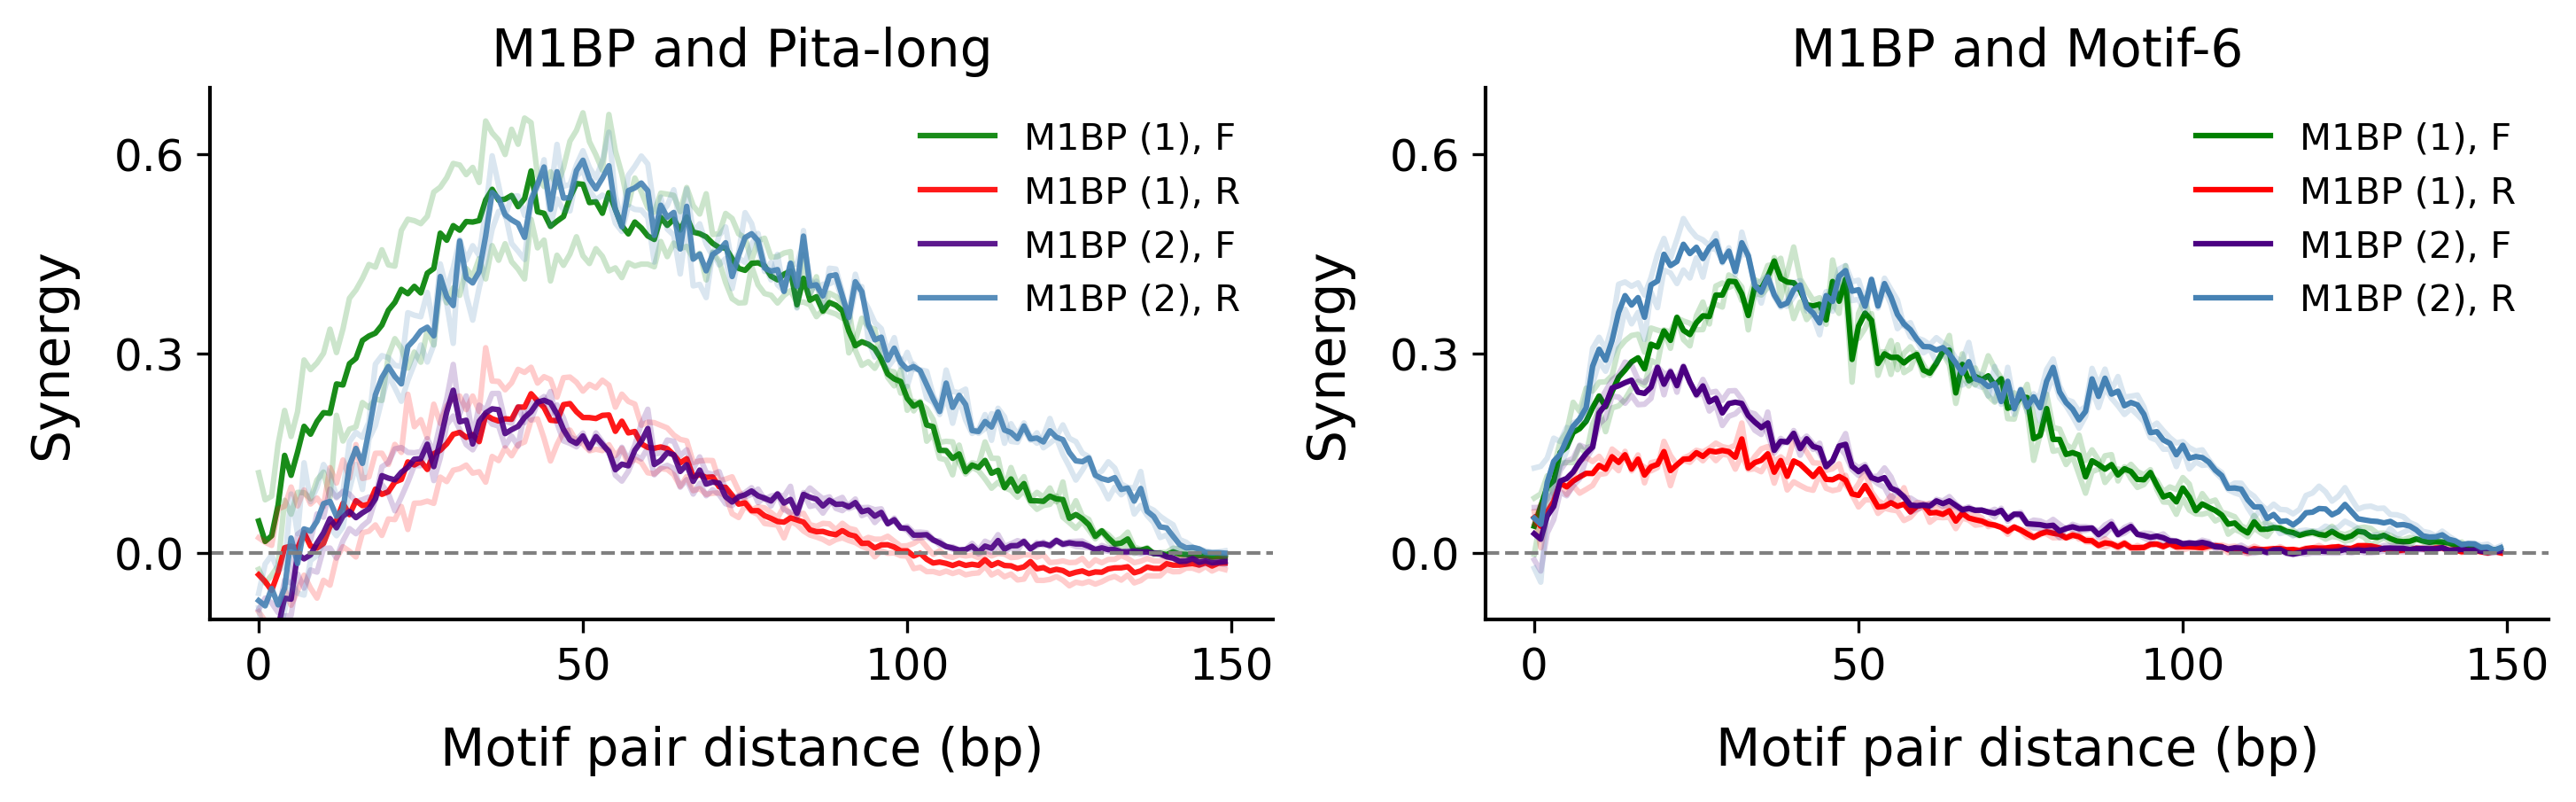

In [30]:

fig, axs = init_subplots_exact(2,1,dpi=300, sharey=True, x_ratios=[1]*2, y_ratios=[0.5])

ax=axs[0]
ylim=[-0.1, 0.7]

mA, mB = 'M1BP', 'Pita-long'

mff = motif_rc_cooperativity_scores[(f'{mA}_fwd', f'{mB}_fwd')][:150]
mfr = motif_rc_cooperativity_scores[(f'{mA}_fwd', f'{mB}_rev')][:150]
mrf = motif_rc_cooperativity_scores[(f'{mA}_rev', f'{mB}_fwd')][:150]
mrr = motif_rc_cooperativity_scores[(f'{mA}_rev', f'{mB}_rev')][:150]
fmf = motif_rc_cooperativity_scores[(f'{mB}_fwd', f'{mA}_fwd')][:150]
rmf = motif_rc_cooperativity_scores[(f'{mB}_rev', f'{mA}_fwd')][:150]
fmr = motif_rc_cooperativity_scores[(f'{mB}_fwd', f'{mA}_rev')][:150]
rmr = motif_rc_cooperativity_scores[(f'{mB}_rev', f'{mA}_rev')][:150]

ax.plot(motif_rc_cooperativity_scores[(f'{mA}_fwd', f'{mB}_fwd')][:150], alpha=0.2, color='green')
ax.plot(motif_rc_cooperativity_scores[(f'{mA}_fwd', f'{mB}_rev')][:150], alpha=0.2, color='green')
ax.plot((mff + mfr)/2, color='green', label='M1BP (1), F', alpha=0.9)

ax.plot(motif_rc_cooperativity_scores[(f'{mA}_rev', f'{mB}_fwd')][:150], alpha=0.2, color='red')
ax.plot(motif_rc_cooperativity_scores[(f'{mA}_rev', f'{mB}_rev')][:150], alpha=0.2, color='red')
ax.plot((mrf + mrr)/2, color='red', label='M1BP (1), R', alpha=0.9)

ax.plot(motif_rc_cooperativity_scores[(f'{mB}_fwd', f'{mA}_fwd')][:150], alpha=0.2, color='#4B0082')
ax.plot(motif_rc_cooperativity_scores[(f'{mB}_rev', f'{mA}_fwd')][:150], alpha=0.2, color='#4B0082')
ax.plot((fmf + rmf)/2, color='#4B0082', label='M1BP (2), F', alpha=0.9)

ax.plot(motif_rc_cooperativity_scores[(f'{mB}_fwd', f'{mA}_rev')][:150], alpha=0.2, color='#4682B4')
ax.plot(motif_rc_cooperativity_scores[(f'{mB}_rev', f'{mA}_rev')][:150], alpha=0.2, color='#4682B4')
ax.plot((fmr + rmr)/2, color='#4682B4', label='M1BP (2), R', alpha=0.9)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
for spine in ['bottom', 'left']:
    ax.spines[spine].set_linewidth(1)
    ax.spines[spine].set_color('black')

ax.set_ylabel("Synergy", fontsize=14, labelpad=10)
ax.set_xlabel('Motif pair distance (bp)', fontsize=14, labelpad=10)
ax.set_title(f'{mA} and {mB}', fontsize=14)
ax.tick_params(axis='both', labelsize=12)
ax.set_ylim(ylim)
ax.legend(ncol=1, fontsize=10, frameon=False, loc="best", 
           handlelength=2)

mA, mB = 'M1BP', 'Motif-6'

ax=axs[1]
# red: mX-FA, green: mX-RB, blue: mY-FB, orange: mY-RA

mff = motif_rc_cooperativity_scores[(f'{mA}_fwd', f'{mB}_fwd')][:150]
mfr = motif_rc_cooperativity_scores[(f'{mA}_fwd', f'{mB}_rev')][:150]
mrf = motif_rc_cooperativity_scores[(f'{mA}_rev', f'{mB}_fwd')][:150]
mrr = motif_rc_cooperativity_scores[(f'{mA}_rev', f'{mB}_rev')][:150]
fmf = motif_rc_cooperativity_scores[(f'{mB}_fwd', f'{mA}_fwd')][:150]
rmf = motif_rc_cooperativity_scores[(f'{mB}_rev', f'{mA}_fwd')][:150]
fmr = motif_rc_cooperativity_scores[(f'{mB}_fwd', f'{mA}_rev')][:150]
rmr = motif_rc_cooperativity_scores[(f'{mB}_rev', f'{mA}_rev')][:150]

ax.plot(motif_rc_cooperativity_scores[(f'{mA}_fwd', f'{mB}_fwd')][:150], alpha=0.2, color='green')
ax.plot(motif_rc_cooperativity_scores[(f'{mA}_fwd', f'{mB}_rev')][:150], alpha=0.2, color='green')
ax.plot((mff + mfr)/2, color='green', label='M1BP (1), F')

ax.plot(motif_rc_cooperativity_scores[(f'{mA}_rev', f'{mB}_fwd')][:150], alpha=0.2, color='red')
ax.plot(motif_rc_cooperativity_scores[(f'{mA}_rev', f'{mB}_rev')][:150], alpha=0.2, color='red')
ax.plot((mrf + mrr)/2, color='red', label='M1BP (1), R')

ax.plot(motif_rc_cooperativity_scores[(f'{mB}_fwd', f'{mA}_fwd')][:150], alpha=0.2, color='#4B0082')
ax.plot(motif_rc_cooperativity_scores[(f'{mB}_rev', f'{mA}_fwd')][:150], alpha=0.2, color='#4B0082')
ax.plot((fmf + rmf)/2, color='#4B0082', label='M1BP (2), F')

ax.plot(motif_rc_cooperativity_scores[(f'{mB}_fwd', f'{mA}_rev')][:150], alpha=0.2, color='#4682B4')
ax.plot(motif_rc_cooperativity_scores[(f'{mB}_rev', f'{mA}_rev')][:150], alpha=0.2, color='#4682B4')
ax.plot((fmr + rmr)/2, color='#4682B4', label='M1BP (2), R')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
for spine in ['bottom', 'left']:
    ax.spines[spine].set_linewidth(1)
    ax.spines[spine].set_color('black')

ax.set_ylabel("Synergy", fontsize=14, labelpad=10)
ax.set_xlabel('Motif pair distance (bp)', fontsize=14, labelpad=10)
ax.set_title(f'{mA} and {mB}', fontsize=14)
ax.tick_params(axis='both', labelsize=12)
ax.set_ylim(ylim)
ax.legend(ncol=1, fontsize=10, frameon=False, loc="best", 
           handlelength=2)

for ax in axs:
    ax.set_yticks([0, 0.3, 0.6])
    ax.set_xticks(np.arange(0,151, 50))
    ax.axhline(0, linestyle='--', color='gray', lw=1)

plt.savefig("plots/m1bp_spacing_preferences.pdf", dpi=300, bbox_inches='tight')
plt.show()

## Motif Sequence Logos

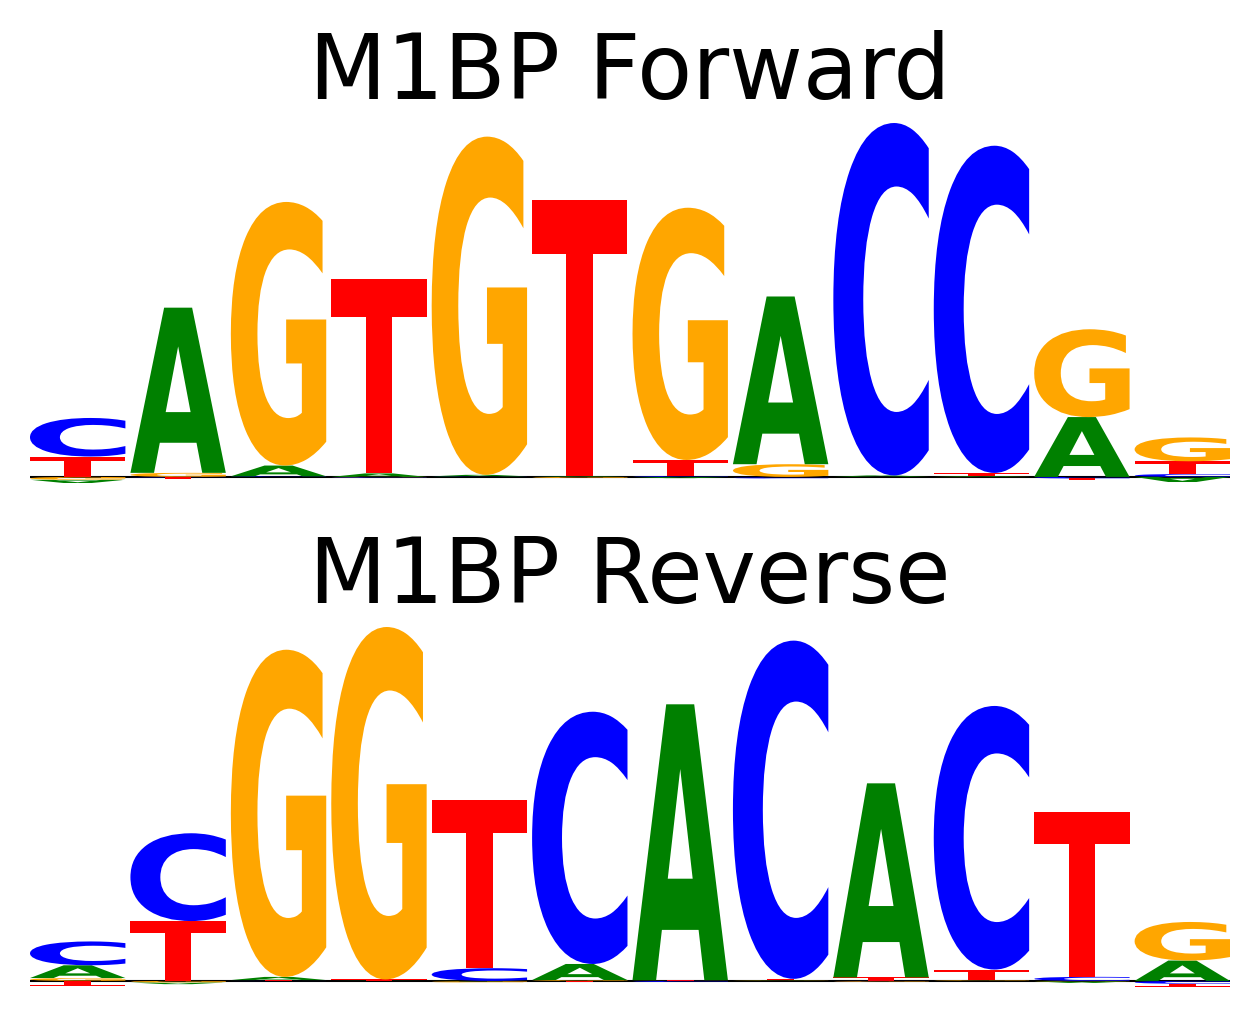

In [45]:
from load_modisco import *

nc14_model_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/'

def get_pattern_matrices(out_folder, TFMODISCO_WINDOW, num_flanking_bases=1):
    h5_file = f"{out_folder}/modisco_results_{TFMODISCO_WINDOW}bp.h5"
    pattern_cwms, pattern_pwms = get_pattern_info(h5_file, num_flanking_bases=num_flanking_bases)
    return pattern_cwms, pattern_pwms
    
nc14_pattern_cwms, nc14_pattern_ppms = get_pattern_matrices(nc14_model_dir + '/ism_report_1_cutoff/', TFMODISCO_WINDOW=600, num_flanking_bases=1)

# %matplotlib inline
M1BP_CWM_fwd = nc14_pattern_cwms['neg_patterns.pattern_2']['fwd']
M1BP_CWM_rev = nc14_pattern_cwms['neg_patterns.pattern_2']['rev']

import logomaker

def trim_cwm_indices(cwm, trim_threshold=0.3, flanking_bases=1):
    # get abs score of each base pair (so this will be of length 30)
    score = np.sum(np.abs(cwm), axis=1) 
    # cut off anything less than 30% of max score
    trim_thresh = np.max(score) * trim_threshold 
    pass_inds = np.where(score >= trim_thresh)[0]
    # include flanking 4 bases left and right
    start, end = max(np.min(pass_inds) - flanking_bases, 0), min(np.max(pass_inds) + flanking_bases + 1, len(score) + 1)
    # trimmed_cwm = cwm[start:end]
    return start, end
    
def plot_weights(array, ax, title=None):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    df = pd.DataFrame(array, columns=['A', 'C', 'G', 'T'])
    df.index.name = 'pos'

    crp_logo = logomaker.Logo(df, ax=ax)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)

    ax.set_yticks([])
    ax.set_xticks([])
    # ax.set_xlabel('Motif Position')
    
    if title:
        ax.set_title(title)
    # plt.show()
    
def final_logo_plot(logo, ax, title):
    plot_weights(logo, ax, title)

%matplotlib inline
fig, axs = init_subplots_exact(2,2,dpi=300, y_ratios=[0.3]*2, yspace=1.4)

for i, (label, cwm) in enumerate(zip(['M1BP Forward', 'M1BP Reverse'], [M1BP_CWM_fwd, M1BP_CWM_rev])):
    start, end = trim_cwm_indices(cwm)    
    final_logo_plot(cwm*-1, axs[i], label)

plt.savefig("plots/m1bp_cwms_directions.pdf", dpi=300, bbox_inches='tight')


## Barplots

In [32]:
import json

with open('/scratch/gpfs/PRITYKIN/brendan/domino/notebook/figures_rerun/fig5_clustermap/all_nc14_pattern_to_target_dict.json', 'r') as f:
    npatterns2targets = json.load(f)

# import clustergram sorted matrix
clustergram_sorted_matrix = pd.read_csv('/scratch/gpfs/PRITYKIN/brendan/domino/notebook/figures_rerun/fig5_clustermap/finalized_nc14_cluster_attributions.csv', index_col=0)
bdf_plot = pd.read_csv('/scratch/gpfs/PRITYKIN/brendan/domino/notebook/figures_rerun/fig5_clustermap/finalized_nc14_cluster_metadata.csv', index_col=0)
sequences_df = pd.read_csv('final_negative_seqlets.csv', index_col=0)

def get_all_pairs_seqlets(mA, mB):
    tmp = clustergram_sorted_matrix.copy()
    
    # get df with all boundaries that have both negative mA and negative mB attribution
    mA_and_mB_df_idx = tmp[(tmp[mA] < 0) & (tmp[mB] < 0)].index
    mA_and_mB_df = bdf_plot.loc[mA_and_mB_df_idx]

    # get forward strands for all these boundaries and sequence information
    fwd_idxs = (mA_and_mB_df.index * 2).tolist()
    mA_seqs = sequences_df.query('motif == @mA and ex_idx % 2 == 0').merge(mA_and_mB_df, on=['chrom', 'start', 'end'])
    mB_seqs = sequences_df.query('motif == @mB and ex_idx % 2 == 0').merge(mA_and_mB_df, on=['chrom', 'start', 'end'])
    
    
    metadata_df = pd.merge(mA_seqs, mB_seqs, on=['chrom', 'start', 'end'], suffixes=(f'_{mA}', f'_{mB}'))
    metadata_df[f'{mA}_order'] = np.where(metadata_df[f"ex_start_{mA}"] < metadata_df[f"ex_start_{mB}"], f"{mA}_A", f"{mA}_B")
    metadata_df[f'{mA}_orientation'] = np.where(metadata_df[f"is_rc_{mA}"] == True, f"{mA}_reverse", f"{mA}_forward")
    metadata_df[f'{mB}_orientation'] = np.where(metadata_df[f"is_rc_{mB}"] == True, f"{mB}_reverse", f"{mB}_forward")
    
    metadata_df['position'] = metadata_df.apply(lambda row: f'{row[f"{mA}_order"]}, {row[f"{mA}_orientation"]}', axis=1)
    
    towards = [f'{mA}_B, {mA}_reverse', f'{mA}_A, {mA}_forward']
    away = [f'{mA}_A, {mA}_reverse', f'{mA}_B, {mA}_forward']
    
    metadata_df['rel_pos'] = metadata_df.apply(lambda row: 'Towards' if row.position in towards else 'Away', axis=1)

    return metadata_df

def get_all_pairs_seqlets_contains_mB(mA, mB='Pita'):
    """
    Use specifically to combine Pita and Pita-long.
    """
    tmp = clustergram_sorted_matrix.copy()

    tmp['Pita'] = tmp['Pita'] + tmp['Pita-long']
    tmp = tmp.drop(columns=['Pita-long'])
    # get df with all boundaries that have both negative mA and negative mB attribution
    mA_and_mB_df_idx = tmp[(tmp[mA] < 0) & (tmp[mB] < 0)].index
    mA_and_mB_df = bdf_plot.loc[mA_and_mB_df_idx]

    # get forward strands for all these boundaries and sequence information
    fwd_idxs = (mA_and_mB_df.index * 2).tolist()
    mA_seqs = sequences_df.query('motif == @mA and ex_idx % 2 == 0').merge(mA_and_mB_df, on=['chrom', 'start', 'end'])
    # example: contains Pita (so can be Pita or Pita-long)
    mB_seqs = sequences_df.query('motif.str.contains(@mB) and ex_idx % 2 == 0').merge(mA_and_mB_df, on=['chrom', 'start', 'end'])
    
    metadata_df = pd.merge(mA_seqs, mB_seqs, on=['chrom', 'start', 'end'], suffixes=(f'_{mA}', f'_{mB}'))
    metadata_df[f'{mA}_order'] = np.where(metadata_df[f"ex_start_{mA}"] < metadata_df[f"ex_start_{mB}"], f"{mA}_A", f"{mA}_B")
    metadata_df[f'{mA}_orientation'] = np.where(metadata_df[f"is_rc_{mA}"] == True, f"{mA}_reverse", f"{mA}_forward")
    metadata_df[f'{mB}_orientation'] = np.where(metadata_df[f"is_rc_{mB}"] == True, f"{mB}_reverse", f"{mB}_forward")
    
    metadata_df['position'] = metadata_df.apply(lambda row: f'{row[f"{mA}_order"]}, {row[f"{mA}_orientation"]}', axis=1)
    
    towards = [f'{mA}_B, {mA}_reverse', f'{mA}_A, {mA}_forward']
    away = [f'{mA}_A, {mA}_reverse', f'{mA}_B, {mA}_forward']
    
    metadata_df['rel_pos'] = metadata_df.apply(lambda row: 'Towards' if row.position in towards else 'Away', axis=1)

    return metadata_df

In [47]:
M1BP_Pita_all_seqlets = get_all_pairs_seqlets('M1BP', 'Pita')
M1BP_contains_Pita_all_seqlets = get_all_pairs_seqlets_contains_mB('M1BP', 'Pita')

In [48]:
M1BP_Pita_all_seqlets.shape, M1BP_contains_Pita_all_seqlets.shape

((40, 60), (64, 60))

51
M1BP and Pita
--------------------
Contingency table
M1BP_orientation  M1BP_forward  M1BP_reverse
M1BP_order                                  
M1BP_A                      26             7
M1BP_B                       6            25

Fisher's Exact Test:
Odds Ratio: 15.476190476190476
p-value: 1.8232162020404535e-06
285
M1BP and Motif-6
--------------------
Contingency table
M1BP_orientation  M1BP_forward  M1BP_reverse
M1BP_order                                  
M1BP_A                     140            11
M1BP_B                      15           145

Fisher's Exact Test:
Odds Ratio: 123.03030303030303
p-value: 3.8505629696664637e-56


/tmp/ipykernel_3728241/368983672.py:53: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(['Away', 'Towards'])


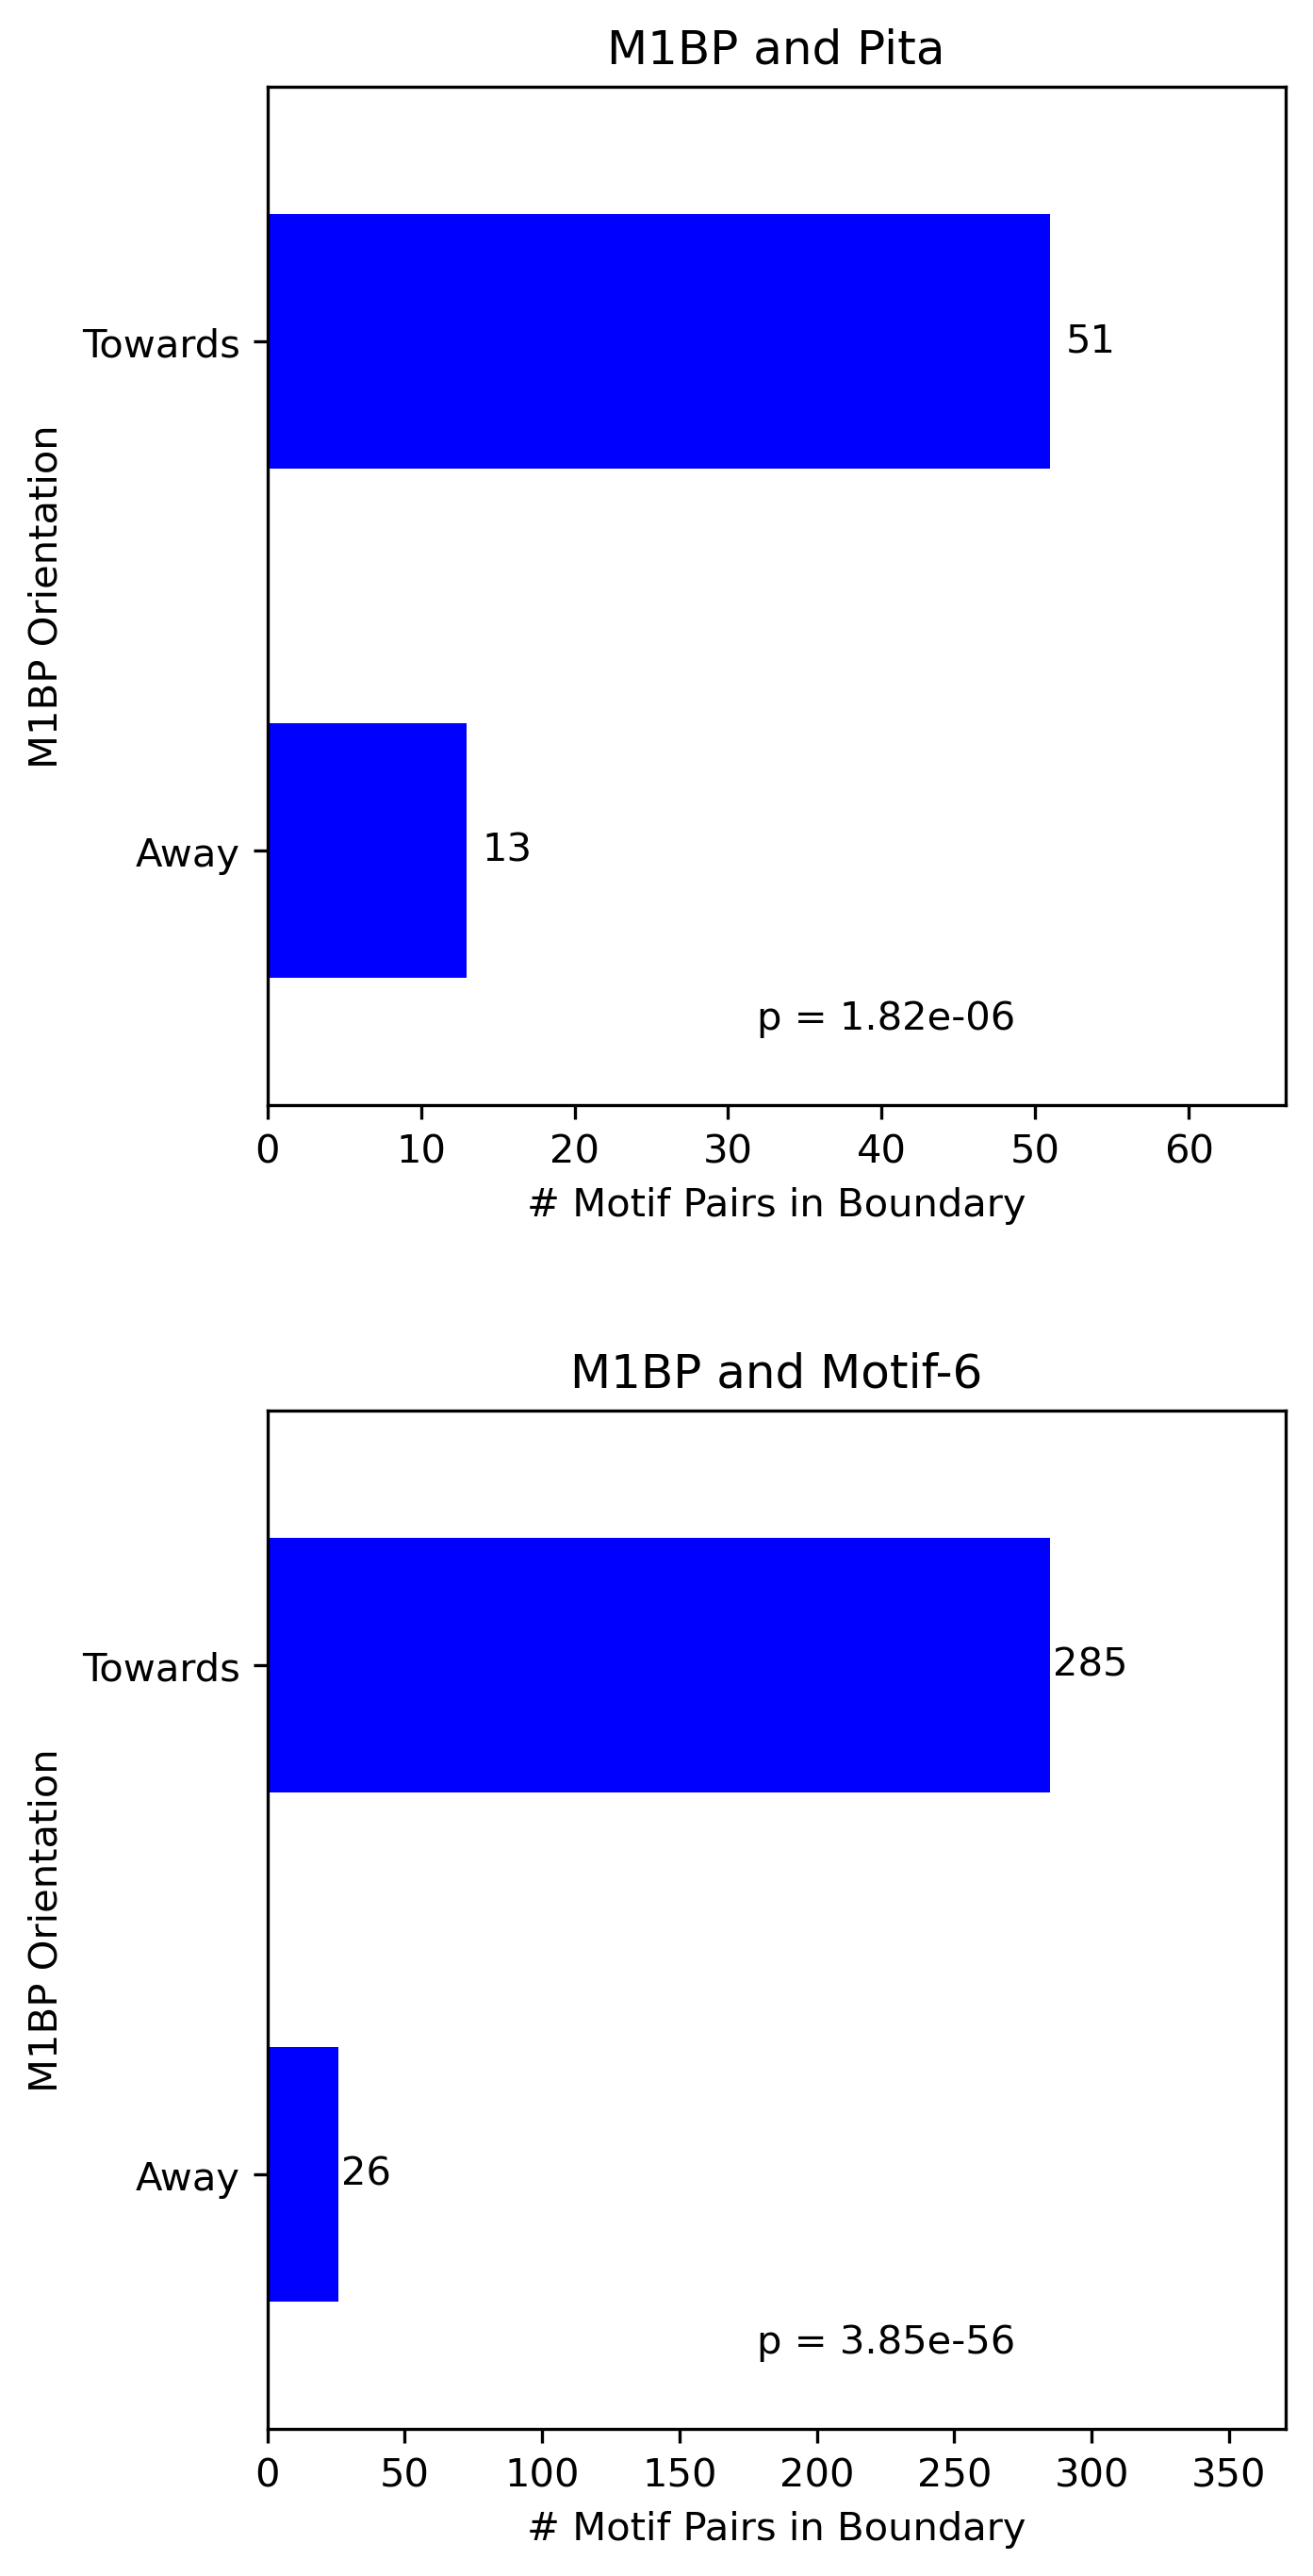

In [36]:
from scipy.stats import fisher_exact
from decimal import Decimal

# plt.rcdefaults()

fig, axs = init_subplots_exact(2,2, dpi=300, y_ratios=[0.9]*2, x_ratios=[0.9], xspace=1.1, yspace=1.3)

for i, motif in enumerate(['Pita', 'Motif-6']):
    # combine Pita and Pita-long
    if motif == 'Pita':
        pairs_seqlets = get_all_pairs_seqlets_contains_mB('M1BP', motif)
    else:
        pairs_seqlets = get_all_pairs_seqlets('M1BP', motif)
    
    ax=axs[i]
    
    vc = pairs_seqlets[['rel_pos']].value_counts()
    print(vc.max())

    # test significance
    contingency = pd.crosstab(pairs_seqlets[f"M1BP_order"], pairs_seqlets[f"M1BP_orientation"])
    print(f"M1BP and {motif}")
    print("----"*5)
    print("Contingency table")
    print(contingency)
    
    # Run Fisher's exact test
    oddsratio, p_value = fisher_exact(contingency, alternative='greater')
    
    print("\nFisher's Exact Test:")
    print("Odds Ratio:", oddsratio)
    print("p-value:", p_value)

    bax = vc.sort_index().plot(kind='barh', ax=ax, color='blue', alpha=1)

    for bar in bax.patches:
        width = bar.get_width()
        bax.text(
            width + 1,                           # x position
            bar.get_y() + bar.get_height()/2,  # y position
            f'{int(width)}',                 # label text
            va='center',
            ha='left'
        )
    
    ax.set_xlabel('# Motif Pairs in Boundary')
    ax.set_xlim(0, vc.max() * 1.3)  # add 20% extra space
    axs[i].text(vc.max() / 1.6, -0.35, f'p = {p_value:.2e}')
    
    axs[i].set_ylabel(f'M1BP Orientation')
    axs[i].set_title(f'M1BP and {motif}')
    for ax in axs:
        ax.set_yticklabels(['Away', 'Towards'])
    
plt.savefig("plots/m1bp_seqlets_validation.pdf", dpi=300, bbox_inches='tight')
plt.show()

# Visualizations of Forward / Forward

In [37]:
from tangermeme.plot import plot_logo
import coolbox
from coolbox.api import *

def plot_locus_with_motif_m1bp(row, motif, s_offset, e_offset, tss_rel_positions=None, save_to=None, ylim=[-0.5, 0.05]):
    X_attr = np.load('/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/numpy_arrs/windowed_attributions.bound_score_gt_1.npy')
    
    fig, ax = init_subplots_exact(1,1,dpi=300, y_ratios=[0.1], x_ratios=[1.5])
    logo = plot_logo(X_attr[row[f"ex_idx_{motif}"]][:, s_offset:e_offset], ax=ax)
    ax.axhline(0, color='w', linewidth=0.3)  # Alternatively, make the line white
    ax.grid(False)
    ax.axvline(row.ex_start_M1BP-s_offset, linewidth=1, c='#f15a24')
    ax.axvline(row[f'ex_start_{motif}']-s_offset, linewidth=1, c='#0071bc')
    ax.axvline(row.ex_end_M1BP-s_offset, linewidth=1, c='#f15a24')
    ax.axvline(row[f'ex_end_{motif}']-s_offset, linewidth=1, c='#0071bc')
    ax.tick_params(axis='both', which='both', length=5)  # Adjust tick length if needed
    ax.set_ylim(ylim)
    
    for spine in ax.spines.values():
        spine.set_visible(True)  
        spine.set_linewidth(0.5)  
        spine.set_edgecolor("black")  
    plt.title(f'{row.M1BP_order} and {row.M1BP_orientation}/{row[f"{motif}_orientation"]}')
    if save_to:
        fig.savefig(save_to, format="pdf", dpi=300, bbox_inches='tight')
    plt.show()

def plot_microc_locus(chrom, start, end, save_to=None):
    HIC_KWARGS = dict(
        style='window', 
        resolution=100, 
        depth_ratio=0.4, 
        cmap='gist_heat_r', 
        norm='no', 
        transform='log10', 
        max_value=0, 
        min_value=-3, 
        grid=False,
    )
    
    frame = [
        coolbox.api.GTF('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/annotations/Drosophila_melanogaster.BDGP6.54.115.gtf',
                                                        row_filter="type == 'gene'", color="#000000"), 
        TrackHeight(4),
        coolbox.api.Spacer(1), 
        
        coolbox.api.Spacer(), coolbox.api.TrackHeight(0.25),
        coolbox.api.HiCMat(f"{MCOOL_DATA_DIR}/nc14_embryo_merged_all_11.mcool", **HIC_KWARGS, title=f"{chrom}:{start-10_000}-{end + 10_000}"),
        coolbox.api.Spacer(), coolbox.api.TrackHeight(0.25),
    
    ]
    from functools import reduce
    
    frame = reduce(lambda x, y: x + y, frame)
    fig = frame.plot(f"{chrom}:{start-10_000}-{end + 10_000}")
    fig.set(facecolor="white")
    if save_to:
        fig.savefig(save_to, format="pdf")
    display(fig)

    

In [38]:
ref_pth = '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/annotations/dm6.refGene.gtf'

annotations_df = pd.read_csv(ref_pth, sep='\t', comment='#', header=None)
annotations_df.columns = ['chrom', 'source', 'feature', 'start', 'end', 'score', 'strand', 'frame', 'attribute']
annotations_df['length'] = annotations_df['end'] - annotations_df['start']

chroms_list = bdf_plot.chrom.value_counts().index.tolist()

annotations_filtered = annotations_df.query('chrom.isin(@chroms_list)').reset_index(drop=True)
annotations_filtered['gene_id'] = annotations_filtered['attribute'].str.extract(r'gene_id "([^"]+)"')
annotations_filtered['transcript_id'] = annotations_filtered['attribute'].str.extract(r'transcript_id "([^"]+)"')
annotations_filtered['gene_name'] = annotations_filtered['attribute'].str.extract(r'gene_name "([^"]+)"')
annotations_filtered.drop('attribute', axis=1, inplace=True)

tss_df = annotations_filtered.query('feature == "transcript" and transcript_id.str.contains("NM") or transcript_id.str.contains("NP")') # filter for protein coding genes
tss_df = tss_df.drop_duplicates('gene_name').reset_index(drop=True)

tss_pos = []
for i, row in tss_df.iterrows():
    if row.strand == "+": tss_pos.append(tss_df.loc[i, 'start'])
    if row.strand == "-": tss_pos.append(tss_df.loc[i, 'end'])
tss_df['tss_position'] = tss_pos

tss_query = tss_df[['chrom', 'tss_position', 'gene_name', 'strand']]

[ERROR:tab.py:300 -                query()] Reference sequence chr2L not found in index header.


2074 2074
-0.9342703414814812


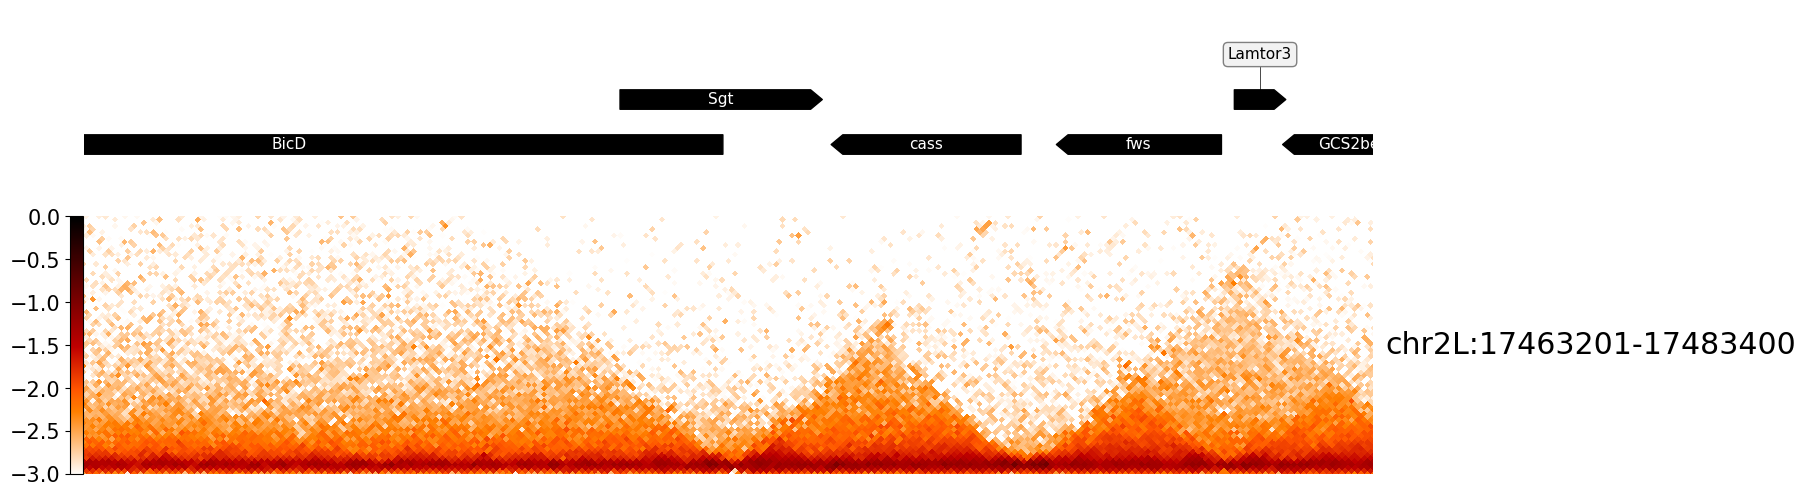

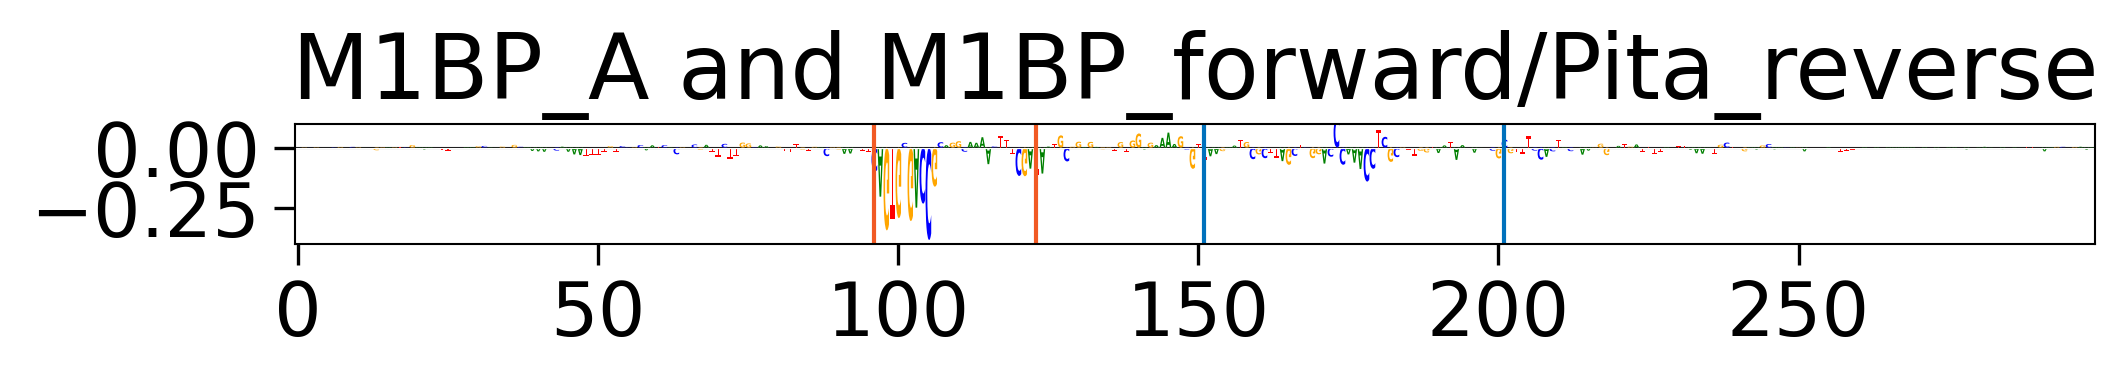

In [39]:
pairs_seqlets = get_all_pairs_seqlets('M1BP', 'Pita')

chrom, start, end = 'chr2L', 17473201, 17473201+199
row = pairs_seqlets.query('chrom == @chrom and start == @start and end == @end').squeeze()
boundary = bdf_plot.query('chrom == @chrom and start == @start and end == @end').squeeze()

print(row.ex_idx_M1BP, row['ex_idx_Pita'])
print(boundary.demeaned_ins_score_1)

plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.size'] = 18

MCOOL_DATA_DIR='/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/mcools/'
RESOLUTION=200
NUM_MERGED=11

# chrom, start, end = "chr2R", 9979319, 9980795
chrom, start, end = boundary.chrom, boundary.start, boundary.end

region_start = boundary.start - 200
region_end = boundary.end + 200
tss_rel_position = tss_query.query('gene_name == "BicD"').tss_position.item() - region_start

plot_microc_locus(chrom, start, end, save_to='plots/M1BP_towards_Pita_microc.pdf')
plot_locus_with_motif_m1bp(row, 'Pita', 100, 400, 
                           tss_rel_positions=[tss_rel_position], 
                           save_to='plots/M1BP_towards_Pita_attr.pdf',
                          ylim=[-0.4, 0.1])

[ERROR:tab.py:300 -                query()] Reference sequence chrX not found in index header.


11052 11052
-0.8156494484061286


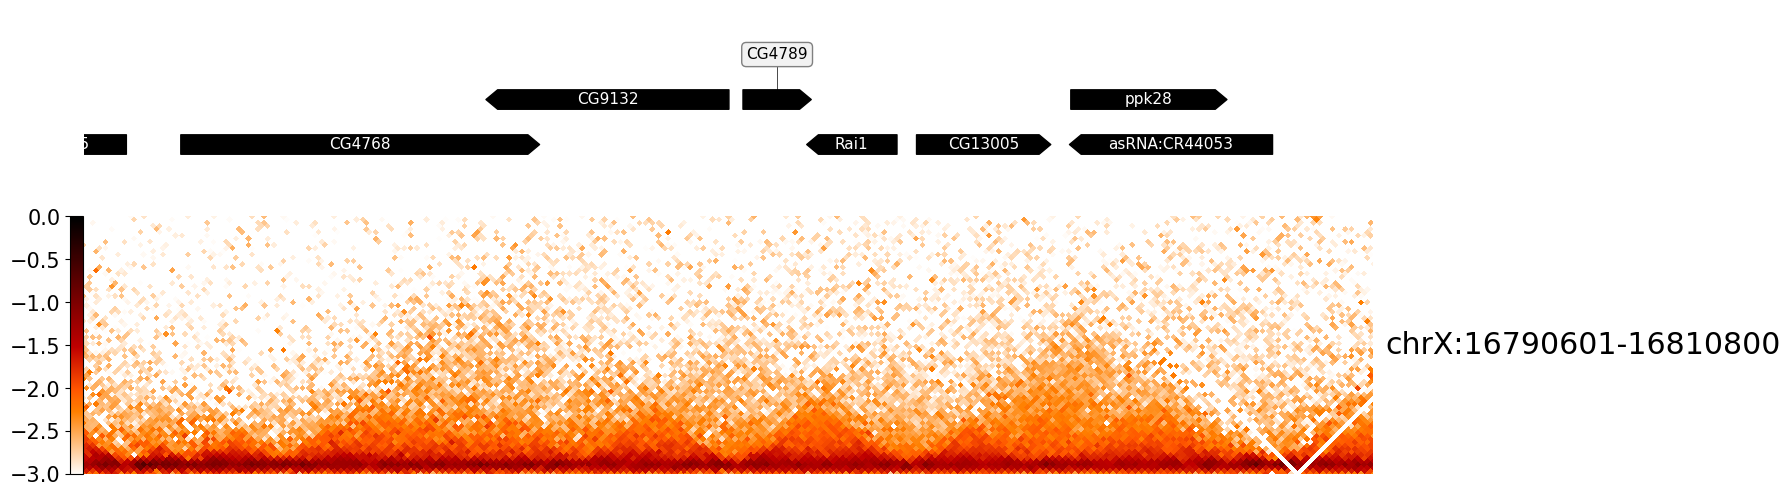

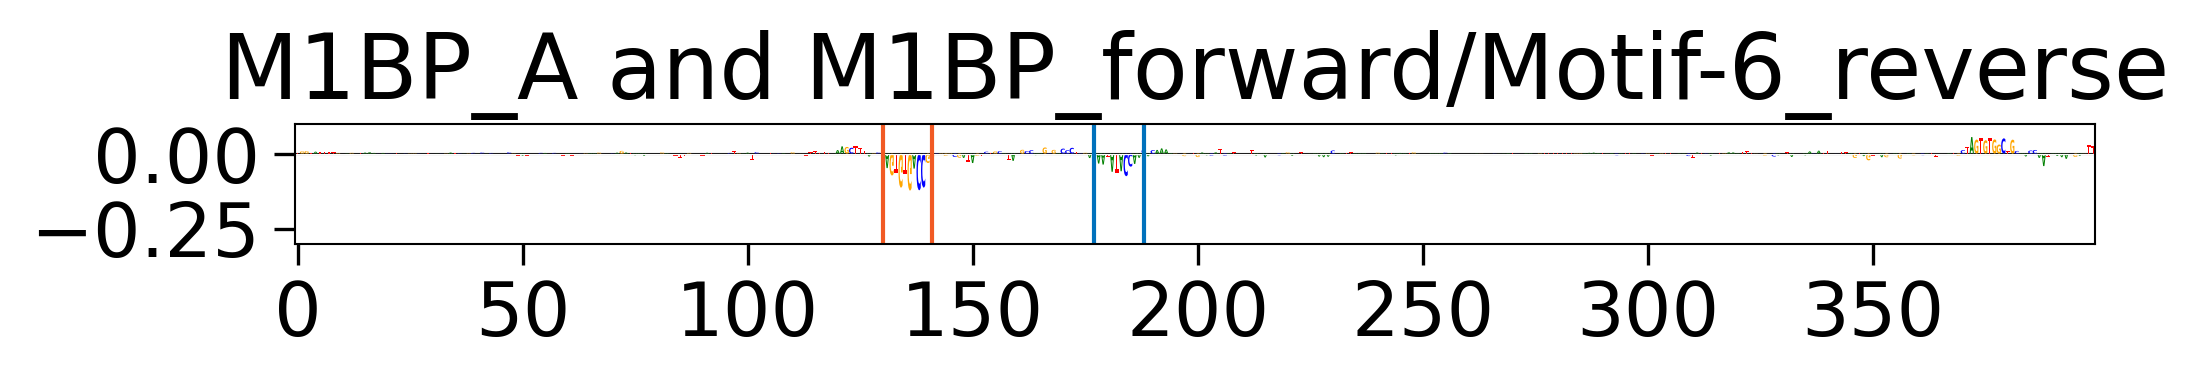

In [40]:
pairs_seqlets = get_all_pairs_seqlets('M1BP', 'Motif-6')


chrom, start, end = 'chrX', 16790601+10000, 16790601+10000+199
row = pairs_seqlets.query('chrom == @chrom and start == @start and end == @end').squeeze()
boundary = bdf_plot.query('chrom == @chrom and start == @start and end == @end').squeeze()

print(row.ex_idx_M1BP, row['ex_idx_Motif-6'])
print(boundary.demeaned_ins_score_1)

plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.size'] = 18

MCOOL_DATA_DIR='/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/mcools/'
RESOLUTION=200
NUM_MERGED=11

chrom, start, end = boundary.chrom, boundary.start, boundary.end

region_start = boundary.start - 200
region_end = boundary.end + 200
CG4789_tss_rel_position = tss_query.query('gene_name == "CG4789"').tss_position.item() - region_start
CG9132_tss_rel_position = tss_query.query('gene_name == "CG9132"').tss_position.item() - region_start

plot_microc_locus(chrom, start, end, save_to='plots/M1BP_towards_M6_microc.pdf')
plot_locus_with_motif_m1bp(row, 'Motif-6', 150, 550, tss_rel_positions=[CG4789_tss_rel_position], 
                           save_to='plots/M1BP_towards_M6_attr.pdf',
                           ylim=[-0.3, 0.1])

## Heatmap of all M1BP sites with Pita and with Motif-6

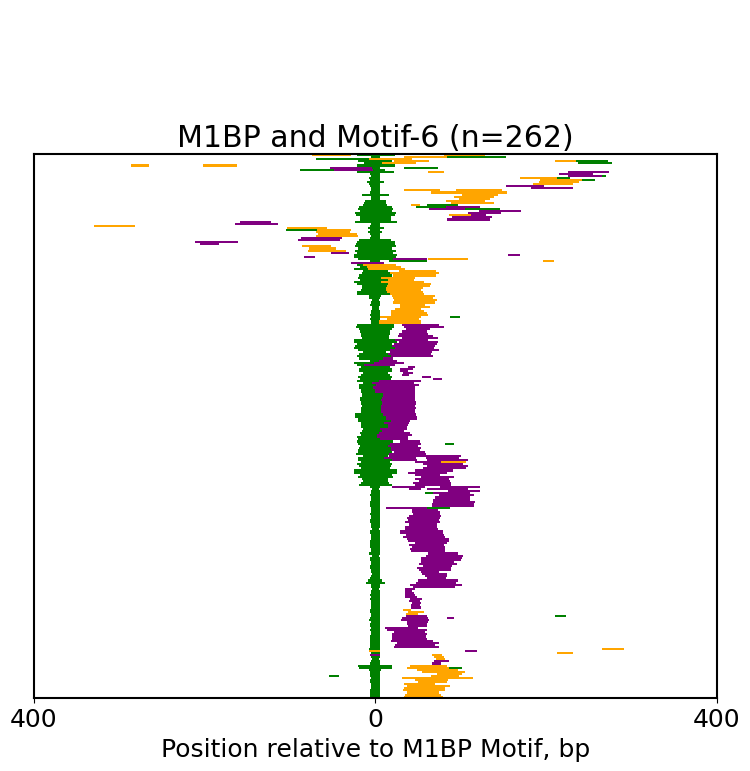

In [48]:
from matplotlib.colors import ListedColormap

mA, mB, figsize = 'M1BP', 'Motif-6', (10, 8)
pairs_seqlets = get_all_pairs_seqlets(mA, mB)

bdf_plot_merge = pairs_seqlets.merge(bdf_plot, on=['chrom', 'start', 'end'])
window_starts = bdf_plot_merge.start.values - 200

centered_around_M1BP_pairs_seqlets = pairs_seqlets.copy()

matrix_width = 800
COUNTER=0

motif_location = np.zeros((centered_around_M1BP_pairs_seqlets.ex_idx_M1BP.unique().shape[0], matrix_width))
m1bp_center_reverse_idxs = []

# loop over each M1BP motif (group) - each group consists of all pairs of motifs (A,B) in the boundary 
# where A != B

# centers everything on one of M1BP motifs (say the first one)
# then for all the motifs in the group, add that seqlet relative to center line defined by this M1BP motif

for counter, (j, group_df) in enumerate(centered_around_M1BP_pairs_seqlets.groupby('ex_idx_M1BP')):
    for i, (_, row) in enumerate(group_df.iterrows()):
        
        # center everything on one of the M1BP motifs
        if i == 0:
            M1BP_midpoint = (row.ex_start_M1BP + row.ex_end_M1BP)//2
            # if the center motif is reverse, add index to thing to be reversed
            if row[f'{mA}_orientation'] == f'{mA}_reverse':
                m1bp_center_reverse_idxs.append(counter)
                      
        astart, aend = row[f'ex_start_{mA}'] + matrix_width//2 - M1BP_midpoint, row[f'ex_end_{mA}'] + matrix_width//2 - M1BP_midpoint
        bstart, bend = row[f'ex_start_{mB}'] + matrix_width//2 - M1BP_midpoint, row[f'ex_end_{mB}'] + matrix_width//2 - M1BP_midpoint

        # Motif-A (M1BP) will always be the same color (color 1) because we force it all to be forward direction
        if row[f'{mA}_orientation'] == f'{mA}_forward':
            motif_location[counter, astart:aend] = 1
        else:
            motif_location[counter, astart:aend] = 1

        # other motif can be forward (color 2) or reverse (color 3)
        if row[f'{mB}_orientation'] == f'{mB}_forward':
            motif_location[counter, bstart:bend] = 2
        else:
            motif_location[counter, bstart:bend] = 3

# flip all rows about x=0 for boundaries where M1BP was in the reverse direction 
motif_location[m1bp_center_reverse_idxs] = motif_location[m1bp_center_reverse_idxs, ::-1]

# change colors 
def swap_values_rows(arr, idx, a, b):
    sub = arr[idx]
    tmp = sub.copy()

    sub[tmp == a] = b
    sub[tmp == b] = a

    arr[idx] = sub
    return arr

# 2 -> 3 and 3 -> 2
motif_location = swap_values_rows(motif_location, m1bp_center_reverse_idxs, 2, 3) 

cmap_dict = {
    0: 'white', 1:'green',
    2:'orange', 3: 'purple', 
} # Example: Blue, Yellow, Red
cmap = ListedColormap([cmap_dict[i] for i in cmap_dict])

from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage

row_dist = pdist(motif_location, metric="hamming")
row_linkage = linkage(row_dist, method="average")

g = sns.clustermap(motif_location, cmap=cmap, col_cluster=False, row_cluster=True, row_linkage=row_linkage,
                   cbar_kws={"ticks": [0, 1, 2, 3]}, figsize=figsize, cbar_pos=None)
custom_labels = ['Other', f'{mA} forward', f'{mB} forward', f'{mB} reverse']
# g.ax_cbar.set_yticklabels(custom_labels) # Use set_xticklabels for a horizontal colorbar
# g.ax_heatmap.set_ylabel("Boundary")
g.ax_heatmap.set_xticks([0, matrix_width//2, matrix_width])
if matrix_width > 1000: 
    g.ax_heatmap.set_xticklabels([f'-{matrix_width/2000}', '0', f'{matrix_width/2000}'], rotation=0)
    g.ax_heatmap.set_xlabel("Position relative to M1BP Motif, kb")
else: 
    g.ax_heatmap.set_xticklabels([f'{matrix_width//2}', '0', f'{matrix_width//2}'], rotation=0)
    g.ax_heatmap.set_xlabel("Position relative to M1BP Motif, bp")
g.ax_heatmap.set_yticks([])
g.ax_heatmap.set_yticklabels([])
g.ax_row_dendrogram.set_visible(False)
g.fig.subplots_adjust(left=0.05)
# g.ax_heatmap.collections[0].set_rasterized(True)

for spine in g.ax_heatmap.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)
    spine.set_edgecolor('black')
    
plt.title(f'{mA} and {mB} (n={len(motif_location)})')

plt.savefig("plots/m1bp_towards_motif6.pdf", dpi=300, bbox_inches='tight', format="pdf")

plt.show()


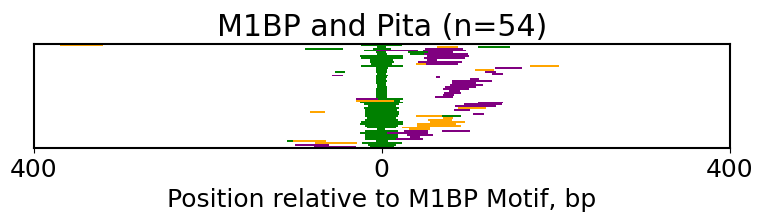

In [49]:
from matplotlib.colors import ListedColormap

mA, mB, figsize = 'M1BP', 'Pita', (10, 2.5)
pairs_seqlets = get_all_pairs_seqlets_contains_mB(mA, mB)

bdf_plot_merge = pairs_seqlets.merge(bdf_plot, on=['chrom', 'start', 'end'])
window_starts = bdf_plot_merge.start.values - 200

centered_around_M1BP_pairs_seqlets = pairs_seqlets.copy()

matrix_width = 800
COUNTER=0

motif_location = np.zeros((centered_around_M1BP_pairs_seqlets.ex_idx_M1BP.unique().shape[0], matrix_width))
m1bp_center_reverse_idxs = []

# loop over each M1BP motif (group) - each group consists of all pairs of motifs (A,B) in the boundary 
# where A != B

# centers everything on one of M1BP motifs (say the first one)
# then for all the motifs in the group, add that seqlet relative to center line defined by this M1BP motif

for counter, (j, group_df) in enumerate(centered_around_M1BP_pairs_seqlets.groupby('ex_idx_M1BP')):
    for i, (_, row) in enumerate(group_df.iterrows()):
        
        # center everything on one of the M1BP motifs
        if i == 0:
            M1BP_midpoint = (row.ex_start_M1BP + row.ex_end_M1BP)//2
            # if the center motif is reverse, add index to thing to be reversed
            if row[f'{mA}_orientation'] == f'{mA}_reverse':
                m1bp_center_reverse_idxs.append(counter)
                      
        astart, aend = row[f'ex_start_{mA}'] + matrix_width//2 - M1BP_midpoint, row[f'ex_end_{mA}'] + matrix_width//2 - M1BP_midpoint
        bstart, bend = row[f'ex_start_{mB}'] + matrix_width//2 - M1BP_midpoint, row[f'ex_end_{mB}'] + matrix_width//2 - M1BP_midpoint

        # Motif-A (M1BP) will always be the same color (color 1) because we force it all to be forward direction
        if row[f'{mA}_orientation'] == f'{mA}_forward':
            motif_location[counter, astart:aend] = 1
        else:
            motif_location[counter, astart:aend] = 1

        # other motif can be forward (color 2) or reverse (color 3)
        if row[f'{mB}_orientation'] == f'{mB}_forward':
            motif_location[counter, bstart:bend] = 2
        else:
            motif_location[counter, bstart:bend] = 3

# flip all rows about x=0 for boundaries where M1BP was in the reverse direction 
motif_location[m1bp_center_reverse_idxs] = motif_location[m1bp_center_reverse_idxs, ::-1]

# change colors 
def swap_values_rows(arr, idx, a, b):
    sub = arr[idx]
    tmp = sub.copy()

    sub[tmp == a] = b
    sub[tmp == b] = a

    arr[idx] = sub
    return arr

# 2 -> 3 and 3 -> 2
motif_location = swap_values_rows(motif_location, m1bp_center_reverse_idxs, 2, 3) 

cmap_dict = {
    0: 'white', 1:'green',
    2:'orange', 3: 'purple', 
} # Example: Blue, Yellow, Red
cmap = ListedColormap([cmap_dict[i] for i in cmap_dict])

from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage

row_dist = pdist(motif_location, metric="hamming")
row_linkage = linkage(row_dist, method="average")

g = sns.clustermap(motif_location, cmap=cmap, col_cluster=False, row_cluster=True, row_linkage=row_linkage,
                   cbar_kws={"ticks": [0, 1, 2, 3]}, figsize=figsize, cbar_pos=None)
custom_labels = ['Other', f'{mA} forward', f'{mB} forward', f'{mB} reverse']
# g.ax_cbar.set_yticklabels(custom_labels) # Use set_xticklabels for a horizontal colorbar
# g.ax_heatmap.set_ylabel("Boundary")
g.ax_heatmap.set_xticks([0, matrix_width//2, matrix_width])
if matrix_width > 1000: 
    g.ax_heatmap.set_xticklabels([f'-{matrix_width/2000}', '0', f'{matrix_width/2000}'], rotation=0)
    g.ax_heatmap.set_xlabel("Position relative to M1BP Motif, kb")
else: 
    g.ax_heatmap.set_xticklabels([f'{matrix_width//2}', '0', f'{matrix_width//2}'], rotation=0)
    g.ax_heatmap.set_xlabel("Position relative to M1BP Motif, bp")
g.ax_heatmap.set_yticks([])
g.ax_heatmap.set_yticklabels([])
g.ax_row_dendrogram.set_visible(False)
g.fig.subplots_adjust(left=0.05)
# g.ax_heatmap.collections[0].set_rasterized(True)

for spine in g.ax_heatmap.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)
    spine.set_edgecolor('black')
    
plt.title(f'{mA} and {mB} (n={len(motif_location)})')

plt.savefig("plots/m1bp_towards_pita.pdf", dpi=300, bbox_inches='tight', format="pdf")

plt.show()
